# RF-ADC interleaving calibration on LBL208

LBL208 version of `doc/zcu208/adc_calibration.ipynb` (whose outputs are the ZCU208 results in
`doc/zcu208/adc_calibration_findings.md`), with step 3b for the LBL analog front end. Hardware check and
commissioning procedure for `ol.adc_cal` (`mimo_mts/drivers/adc_calibration.py`),
following PG269 *RF-ADC Calibration Mechanism*.

| Block | Corrects | After RF-ADC startup |
|---|---|---|
| OCB1 | sub-ADC offset | tracks in the background, cannot be frozen |
| OCB2 | offset, sampling-switch skew | set by foreground calibration, then frozen |
| GCB | sub-ADC gain | tracks; needs input above -40 dBFS; can be frozen |
| TSCB | sub-ADC time skew | tracks; needs input above -40 dBFS; can be frozen |

Writing coefficients enables the driver's per-block **override**: written values stay in use until
`release_override()`.

### Where to look for interleaving spurs
With M interleaved sub-ADCs, mismatch produces spurs at k·Fs/M (offset) and k·Fs/M − f_in (gain and time
skew). At Fs = 4 GHz the strongest gain/skew image is at Fs/2 − f_in, which in the 2nd Nyquist zone appears at
**6000 MHz − f_in**, i.e. mirrored about 3000 MHz.

* At f_in = **3000 MHz** that image falls exactly on the carrier, and all other spurs are ≥ 500 MHz away, outside
  the ±250 MHz band left after the RFDC decimation by 8. Calibration then has no visible effect (first run).
* At f_in = **2973 MHz** the image is at 3027 MHz, 54 MHz from the carrier and inside the band.

So the test tone is placed off 3000 MHz, and each step reports the level at the predicted spur frequencies.

### Setup
* Restart the kernel and run all cells in order; step 1 must load a fresh overlay.
* `ALS_LLRF_LBL208` overlay (CLK104A): ADC NCO 3000 MHz (2nd Nyquist zone), decimation 8 → captures at 500 MSPS.
* One DAC looped back to one ADC through the analog front end (RX slices 4–7); step 3b finds the channel and sets
  its attenuation. The LLRF amplitude setpoint generates the CW tone.
* Steps marked **[check]** answer open hardware questions; please keep their outputs.

In [1]:
%cd /home/xilinx/jupyter_notebooks/pynq_llrf/

/home/xilinx/jupyter_notebooks/pynq_llrf_MR37


In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mimo_mts.overlay import MimoMtsOverlay

%load_ext autoreload
%autoreload 2

In [3]:
CONFIG = "ALS_LLRF_LBL208"  # LLRF amplitude setpoint provides a CW tone
ADC_CH = 0  # ADC channel under test; step 3b sets it to the loopback channel
F_CW_MHZ = 2973.0  # test tone; avoid exactly 3000 MHz (= 3 Fs/4), see above
M_SUB = 8  # assumed sub-ADC interleave factor; its spur set also covers M = 2 and 4
# Scratch file for this test. The IOCs default to /etc/mimo_mts/adc_cal.json; do not overwrite it here.
CAL_FILE = Path("/tmp/adc_cal_test.json")
N_AVG = 4  # captures averaged per spectrum
TRIG_WAIT_S = 0.6  # > one trigger period

## 1. Load overlay

In [4]:
ol = MimoMtsOverlay(config=CONFIG)
cal = ol.adc_cal
fs_hz = ol.adc_sampling_rate
fs_cap_hz = fs_hz / ol.ol_info["rfdc"]["adc_decimation_factor"]  # rate of the captured samples
print(cal)
print(f"Fs = {fs_hz / 1e9} GHz, capture rate = {fs_cap_hz / 1e6} MSPS")
print(f"ADC mixer: {ol.adc_mixer_nco_freq_mhz} MHz, Nyquist zone {ol.adc_mixer_nco_nyquist}")

<AdcCalibration: ADC channels [0, 1, 2, 3, 4, 5, 6, 7]>
Fs = 4.0 GHz, capture rate = 500.0 MSPS
ADC mixer: 3000 MHz, Nyquist zone 2


## 2. State after RF-ADC startup

First run: not frozen and `DisableFreezePin=0`, as PG269 describes.

In [5]:
print("raw CalFreeze:", cal.block(ADC_CH).CalFreeze)
print("frozen:       ", cal.is_frozen())
print("cal. mode:    ", cal.calibration_mode())
print(cal.report(ADC_CH))

raw CalFreeze: {'CalFrozen': 0, 'DisableFreezePin': 0, 'FreezeCalibration': 0}
frozen:        {0: False, 1: False, 2: False, 3: False, 4: False, 5: False, 6: False, 7: False}
cal. mode:     {0: 2, 1: 2, 2: 2, 3: 2, 4: 2, 5: 2, 6: 2, 7: 2}
ADC0 (tile 0, block 0): tracking
  OCB1: [4290576327, 4292607983, 983073, 4293066742, 0, 0, 0, 0]
  OCB2: [9371789, 10027147, 9437302, 7864461, 0, 0, 0, 0]
  GCB : [131072, 65538, 196610, 65538, 0, 0, 0, 0]
  TSCB: [33489407, 33489389, 33489407, 33489407, 33489407, 33488899, 33489407, 33489124]


## 3. Trigger and CW tone (DAC loopback)

`enable_cw()` zeroes the DAC waveform buffer and uses the LLRF amplitude setpoint as a CW source, then moves the
DAC NCO so the tone is at `F_CW_MHZ`. Call it again after reloading the overlay.

The amplitude/phase loops must stay open, otherwise they react to the tone being off the 3000 MHz NCO.

In [6]:
def enable_cw(f_mhz=F_CW_MHZ):
    rm = ol.rf_control.register_map
    rm.trig_sel = 0  # internal trigger
    rm.trig_period = 125e6  # 2 Hz at 250 MHz
    rm.trig_delay = 0
    rm.trig_divide = 1
    rm.dac_enable = 1
    rm.pulse_length = 0xFFF
    ol.dac_player[:] = np.zeros(ol.dac_player.size, dtype=np.int16)
    rm.amp_loop_setpoint = 32767 / ol.rf_control.tx_gain
    rm.phs_loop_setpoint = 0
    # DAC in the 2nd Nyquist zone: NCO at -f gives a tone at +f (config uses -3000 for 3000 MHz)
    ol.dac_mixer_nco_freq_mhz = -f_mhz
    print(f"loops: amp_loop_enable={int(rm.amp_loop_enable)}, phs_loop_enable={int(rm.phs_loop_enable)}")
    print(f"DAC mixer: {ol.dac_mixer_nco_freq_mhz} MHz, Nyquist zone {ol.dac_mixer_nco_nyquist}")
    if "rx_attenuation" in globals():  # LBL208 front end, chosen in step 3b; re-applied after each overlay load
        apply_rx_attenuation()


enable_cw()

loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -2973.0 MHz, Nyquist zone 2


## 3b. LBL208 analog front end: find the loopback ADC and set its attenuation

Only for overlays with the LBL front end (`ol.ffe`, e.g. `ALS_LLRF_LBL208`); skipped otherwise. One DAC is looped back
to one ADC through the front end's RX slices 4–7, which have a pre-filter and a post-filter HMC1122 attenuator per ADC
(0–31.5 dB, see `doc/lbl208/als_llrf_mts_ffe.ipynb`). The attenuators are not set at power-up, so their state is
unknown.

The cell starts all RX attenuators at the maximum and lowers them together until one ADC stands at least 20 dB above
the others, sets `ADC_CH` to that channel, then sets its attenuation for about `TARGET_DBFS` (well above the -40 dBFS
GCB/TSCB need, below clipping). `enable_cw()` re-applies the result after every overlay reload. Run step 4 after this
cell so its helpers use the detected `ADC_CH`.

In [7]:
TARGET_DBFS = -15.0
RX_STEPS_DB = (31.5, 20, 10, 5, 0)


def set_rx(adc, pre=None, post=None):
    """FFE RX attenuators of one ADC: slice adc // 2 + 4, attenuators (pre, post) = (0, 1) or (2, 3)."""
    sl = ol.ffe.slices[adc // 2 + 4]
    if pre is not None:
        sl.attenuators[(adc % 2) * 2].set_db(pre)
    if post is not None:
        sl.attenuators[(adc % 2) * 2 + 1].set_db(post)


def apply_rx_attenuation():
    for adc, (pre, post) in rx_attenuation.items():
        set_rx(adc, pre, post)


def adc_dbfs_all(timeout_s=60):
    """RMS level of every ADC channel in dBFS; waits through all-zero captures after an overlay load."""
    t0 = time.monotonic()
    while True:
        time.sleep(TRIG_WAIT_S)
        i, q = ol.capture_adc_iq_buf()
        if np.any(i) or np.any(q):
            rms = np.sqrt(np.mean(i.astype(float) ** 2 + q.astype(float) ** 2, axis=1))
            return 20 * np.log10(rms / 32768 + 1e-12)
        if time.monotonic() - t0 > timeout_s:
            raise RuntimeError(f"ADC captures still all zeros after {timeout_s} s")


if hasattr(ol, "ffe"):
    rx_adcs = [a for a in range(8) if ol.ffe.slices[a // 2 + 4].is_present()]
    print("ADCs with an RX slice:", rx_adcs)
    for atten in RX_STEPS_DB:
        for a in rx_adcs:
            set_rx(a, pre=atten, post=atten)
        p = adc_dbfs_all()
        print(f"RX attenuation {atten:4.1f} dB:", "  ".join(f"ADC{a} {p[a]:6.1f}" for a in rx_adcs))
        if p[rx_adcs].max() - np.median(p[rx_adcs]) > 20 and p[rx_adcs].max() > -40:
            break
    ADC_CH = max(rx_adcs, key=lambda a: p[a])
    print(f"loopback on ADC{ADC_CH}: {p[ADC_CH]:.1f} dBFS with pre = post = {atten} dB")

    # Move the loopback channel towards TARGET_DBFS: change the post-filter attenuator first, then the pre-filter one
    change = p[ADC_CH] - TARGET_DBFS  # > 0: too strong, attenuate more
    post = min(max(atten + round(change * 2) / 2, 0.0), 31.5)
    pre = min(max(atten + round((change - (post - atten)) * 2) / 2, 0.0), 31.5)
    rx_attenuation = {ADC_CH: (pre, post)}
    apply_rx_attenuation()
    p = adc_dbfs_all()
    print(f"ADC{ADC_CH}: pre {pre} dB, post {post} dB -> {p[ADC_CH]:.1f} dBFS (target {TARGET_DBFS})")
else:
    print("no LBL analog front end in this overlay; skipping")

ADCs with an RX slice: [0, 1, 2, 3, 4, 5, 6, 7]
RX attenuation 31.5 dB: ADC0  -72.4  ADC1  -72.0  ADC2  -72.6  ADC3  -71.7  ADC4  -71.9  ADC5  -72.4  ADC6  -72.2  ADC7  -63.5
RX attenuation 20.0 dB: ADC0  -72.3  ADC1  -71.9  ADC2  -72.4  ADC3  -71.7  ADC4  -72.0  ADC5  -72.5  ADC6  -72.0  ADC7  -36.1
loopback on ADC7: -36.1 dBFS with pre = post = 20 dB
ADC7: pre 19.0 dB, post 0.0 dB -> -36.1 dBFS (target -15.0)


## 4. Spectrum and spur measurement

`expected_spurs()` lists the interleaving spurs (for `M_SUB`) that fall inside the captured band. `measure()`
reads the level at each, plus the carrier, and warns if the carrier is not where `F_CW_MHZ` puts it (wrong
frequency axis or tone setting).

In [8]:
def capture(ch=ADC_CH, timeout_s=60):
    """One capture; waits while the buffer is all zeros (the internal trigger can take many seconds after load)."""
    t0 = time.monotonic()
    while True:
        time.sleep(TRIG_WAIT_S)
        i, q = ol.capture_adc_iq_buf()
        if np.any(i[ch]) or np.any(q[ch]):
            return i[ch].astype(np.float64) + 1j * q[ch].astype(np.float64)
        if time.monotonic() - t0 > timeout_s:
            raise RuntimeError(f"ADC{ch} capture still all zeros after {timeout_s} s: no trigger/capture")


def spectrum_dbfs(ch=ADC_CH, n_avg=N_AVG):
    psd = 0
    for _ in range(n_avg):
        x = capture(ch)
        win = np.blackman(len(x))
        psd = psd + np.abs(np.fft.fftshift(np.fft.fft(x * win)) / win.sum()) ** 2
    dbfs = 10 * np.log10(psd / n_avg / 32768.0**2 + 1e-30)
    f_mhz = np.fft.fftshift(np.fft.fftfreq(len(x), 1 / fs_cap_hz)) / 1e6 + ol.adc_mixer_nco_freq_mhz
    return f_mhz, dbfs


def to_rf_mhz(f_mhz):
    """Fold any frequency to the 1st Nyquist zone, then map it into the ADC's Nyquist zone."""
    fs = fs_hz / 1e6
    f = np.mod(f_mhz, fs)
    f1 = np.minimum(f, fs - f)
    zone = ol.adc_mixer_nco_nyquist
    return (zone - 1) * fs / 2 + (f1 if zone % 2 == 1 else fs / 2 - f1)


def expected_spurs(f_in=F_CW_MHZ, m=M_SUB):
    """Interleaving spurs inside the captured band: {label: RF frequency in MHz}."""
    fs = fs_hz / 1e6
    lo = ol.adc_mixer_nco_freq_mhz - 0.4 * fs_cap_hz / 1e6  # stay inside the decimation passband
    hi = ol.adc_mixer_nco_freq_mhz + 0.4 * fs_cap_hz / 1e6
    spurs = {}
    for k in range(1, m):
        for label, f in ((f"{k}Fs/{m}", k * fs / m), (f"{k}Fs/{m}-fin", k * fs / m - f_in)):
            rf = float(to_rf_mhz(f))
            if lo <= rf <= hi and abs(rf - f_in) > 1 and rf not in spurs.values():
                spurs[label] = rf
    return spurs


def level_at(f_mhz, dbfs, f0, half_width_bins=3):
    k = int(np.argmin(np.abs(f_mhz - f0)))
    sl = slice(max(0, k - half_width_bins), k + half_width_bins + 1)
    j = sl.start + int(np.argmax(dbfs[sl]))
    return f_mhz[j], dbfs[j]


def measure(label, ch=ADC_CH):
    f, d = spectrum_dbfs(ch)
    f_peak = f[int(np.argmax(d))]
    if abs(f_peak - F_CW_MHZ) > 1:
        print(f"WARNING: strongest tone at {f_peak:.3f} MHz, expected {F_CW_MHZ} MHz")
    _, carrier = level_at(f, d, F_CW_MHZ)
    row = {"carrier dBFS": round(carrier, 1)}
    print(f"--- {label}: carrier {carrier:.1f} dBFS")
    for name, f0 in expected_spurs().items():
        fm, p = level_at(f, d, f0)
        row[f"{name} @ {f0:.0f} MHz (dBc)"] = round(p - carrier, 1)
        print(f"    {name:>12s} {fm:10.3f} MHz {p:7.1f} dBFS {p - carrier:7.1f} dBc")
    table[label] = row
    spectra[label] = (f, d)


table, spectra = {}, {}
print("expected spurs in band:", expected_spurs())

expected spurs in band: {'2Fs/8': 3000.0, '4Fs/8-fin': 3027.0}


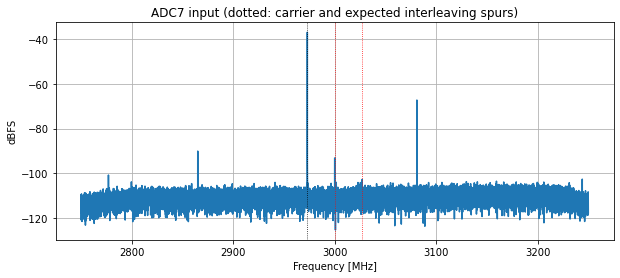

In [9]:
f, d = spectrum_dbfs()
plt.figure(figsize=(10, 4))
plt.plot(f, d)
for f0 in expected_spurs().values():
    plt.axvline(f0, color="r", ls=":", lw=0.8)
plt.axvline(F_CW_MHZ, color="k", ls=":", lw=0.8)
plt.xlabel("Frequency [MHz]")
plt.ylabel("dBFS")
plt.title(f"ADC{ADC_CH} input (dotted: carrier and expected interleaving spurs)")
plt.grid(True)

## 5. Untrained: GCB/TSCB as left by startup

Freeze immediately so the startup values are kept, and measure. This is the reference without training.

In [10]:
cal.freeze()
measure("untrained (startup)")

--- untrained (startup): carrier -37.1 dBFS
           2Fs/8   3000.000 MHz   -96.6 dBFS   -59.5 dBc
       4Fs/8-fin   3026.993 MHz  -104.4 dBFS   -67.3 dBc


## 6. Train: track the CW tone, then freeze and save

PG269 time constants are 2^20 to 2^22 samples (about 1 ms at 4 GSPS); a few seconds is plenty.

In [11]:
print(cal.unfreeze())
time.sleep(5)
measure("tracking")

{0: False, 1: False, 2: False, 3: False, 4: False, 5: False, 6: False, 7: False}
--- tracking: carrier -37.1 dBFS
           2Fs/8   3000.000 MHz   -99.8 dBFS   -62.7 dBc
       4Fs/8-fin   3026.993 MHz  -103.9 dBFS   -66.8 dBc


In [12]:
print(cal.freeze())
print("raw CalFreeze:", cal.block(ADC_CH).CalFreeze)
cal.save(CAL_FILE)
measure("trained + frozen")
print(json.dumps(cal.load(CAL_FILE)[f"ADC{ADC_CH}"]["coeffs"]))

{0: True, 1: True, 2: True, 3: True, 4: True, 5: True, 6: True, 7: True}
raw CalFreeze: {'CalFrozen': 1, 'DisableFreezePin': 1, 'FreezeCalibration': 1}
--- trained + frozen: carrier -37.1 dBFS
           2Fs/8   3000.000 MHz  -100.7 dBFS   -63.7 dBc
       4Fs/8-fin   3027.008 MHz  -102.3 dBFS   -65.2 dBc
{"OCB1": [4291624921, 4292083683, 4294770717, 327671, 0, 0, 0, 0], "OCB2": [4294705099, 4294377412, 4292870079, 4294770647, 0, 0, 0, 0], "GCB": [266207239, 266670011, 267849719, 528347, 0, 0, 0, 0], "TSCB": [3014665, 3932192, 4390923, 262203, 4784139, 3145760, 4849693, 1966146]}


## 7. [check] Does a TSCB write take effect?

In the first run, GCB writes read back correctly but TSCB writes did not. The driver writes and reads the same
TSCB registers (offset `0x170`, 9-bit value, bit 15 = override enable), so the raw registers tell us:

* bit 15 set and value = written → read-back works (contradicts the first run);
* bit 15 set, value ≠ written → hardware returns the live value; the override may still act, check the spectrum;
* bit 15 clear → the write did not take.

In [13]:
def tscb_raw(ch=ADC_CH):
    """Raw TSCB registers per sub-ADC slice, via the RFDC AXI-Lite (XRFDC_BLOCK_BASE + 0x170)."""
    tile, block = cal.channels[ch]
    hs = ol.board.converters_per_tile == 2  # 4 GSPS dual-ADC tiles: 2 slices per block
    slices = [2 * block, 2 * block + 1] if hs else [block]
    out = {}
    for s in slices:
        base = 0x16000 + tile * 0x4000 + s * 0x400 + 0x170
        regs = [ol.rfdc.read(base + 4 * i) & 0xFFFF for i in range(8)]
        out[f"slice{s}"] = [f"en={r >> 15} val=0x{r & 0x1FF:03x}" for r in regs]
    return out


def pack(value):
    """Same 9-bit value for every slice of a coefficient."""
    return (value << 16 | value) if ol.board.converters_per_tile == 2 else value


print("before:", tscb_raw())
TEST = 0x010
cal.write({ADC_CH: {"TSCB": [pack(TEST)] * 8}})
print("after write 0x010:", tscb_raw())
print("driver read-back:", cal.read(ADC_CH, ["TSCB"]))
measure("TSCB = 0x010")

before: {'slice2': ['en=0 val=0x009', 'en=0 val=0x020', 'en=0 val=0x00b', 'en=0 val=0x03b', 'en=0 val=0x00b', 'en=0 val=0x020', 'en=0 val=0x01d', 'en=0 val=0x042'], 'slice3': ['en=0 val=0x02e', 'en=0 val=0x03c', 'en=0 val=0x043', 'en=0 val=0x004', 'en=0 val=0x049', 'en=0 val=0x030', 'en=0 val=0x04a', 'en=0 val=0x01e']}
after write 0x010: {'slice2': ['en=1 val=0x009', 'en=1 val=0x020', 'en=1 val=0x00b', 'en=1 val=0x03b', 'en=1 val=0x00b', 'en=1 val=0x020', 'en=1 val=0x01d', 'en=1 val=0x042'], 'slice3': ['en=1 val=0x02e', 'en=1 val=0x03c', 'en=1 val=0x043', 'en=1 val=0x004', 'en=1 val=0x049', 'en=1 val=0x030', 'en=1 val=0x04a', 'en=1 val=0x01e']}
driver read-back: {7: {'TSCB': [3014665, 3932192, 4390923, 262203, 4784139, 3145760, 4849693, 1966146]}}
--- TSCB = 0x010: carrier -37.1 dBFS
           2Fs/8   3000.000 MHz  -104.1 dBFS   -67.0 dBc
       4Fs/8-fin   3026.993 MHz  -102.7 dBFS   -65.6 dBc


## 8. Demonstrate: overwrite GCB with zeros

GCB read-back is known to work. Zeroing it (override on) should raise the gain image if the trained values matter.

In [14]:
cal.restore(CAL_FILE)
cal.write({ADC_CH: {"GCB": [0] * 8}})
measure("GCB = 0")

--- GCB = 0: carrier -37.1 dBFS
           2Fs/8   3000.000 MHz   -95.2 dBFS   -58.1 dBc
       4Fs/8-fin   3026.993 MHz   -99.5 dBFS   -62.4 dBc


## 9. Restore and verify

`restore()` writes GCB/TSCB from the file (override on), freezes, and verifies by read-back. OCB1 keeps tracking and
is not compared here.

In [15]:
print(cal.restore(CAL_FILE))
measure("restored")

{0: [], 1: [], 2: [], 3: [], 4: [], 5: [], 6: [], 7: []}
--- restored: carrier -37.1 dBFS
           2Fs/8   3000.000 MHz   -95.8 dBFS   -58.7 dBc
       4Fs/8-fin   3026.993 MHz  -103.9 dBFS   -66.8 dBc


## 10. Release override and resume tracking

In [16]:
cal.release_override()
print(cal.unfreeze())
time.sleep(5)
measure("released + tracking")

{0: False, 1: False, 2: False, 3: False, 4: False, 5: False, 6: False, 7: False}
--- released + tracking: carrier -37.1 dBFS
           2Fs/8   3000.000 MHz   -94.7 dBFS   -57.6 dBc
       4Fs/8-fin   3026.993 MHz  -104.8 dBFS   -67.8 dBc


## 11. [check] Restore after a fresh overlay load

The production flow (`AlsLlrfLBL208`): load the overlay, restore, freeze. Compare with "restored" in step 9.

In [17]:
ol.free()
ol = MimoMtsOverlay(config=CONFIG)
cal = ol.adc_cal
print("after reload, frozen:", cal.is_frozen())
enable_cw()

after reload, frozen: {0: False, 1: False, 2: False, 3: False, 4: False, 5: False, 6: False, 7: False}
loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -2973.0 MHz, Nyquist zone 2


In [18]:
measure("reload, untrained")
print(cal.restore(CAL_FILE))
measure("reload + restore")
print("TSCB raw:", tscb_raw())

--- reload, untrained: carrier -65.2 dBFS
           2Fs/8   3000.000 MHz   -86.1 dBFS   -20.9 dBc
       4Fs/8-fin   3026.993 MHz  -100.9 dBFS   -35.8 dBc
{0: [], 1: [], 2: [], 3: [], 4: [], 5: [], 6: [], 7: []}
--- reload + restore: carrier -65.2 dBFS
           2Fs/8   3000.000 MHz   -87.4 dBFS   -22.3 dBc
       4Fs/8-fin   3027.008 MHz  -101.5 dBFS   -36.4 dBc
TSCB raw: {'slice2': ['en=1 val=0x15b', 'en=1 val=0x1e0', 'en=1 val=0x1ff', 'en=1 val=0x091', 'en=1 val=0x003', 'en=1 val=0x16a', 'en=1 val=0x1ff', 'en=1 val=0x04d'], 'slice3': ['en=1 val=0x1ff', 'en=1 val=0x0f6', 'en=1 val=0x1f4', 'en=1 val=0x024', 'en=1 val=0x1f6', 'en=1 val=0x040', 'en=1 val=0x1ff', 'en=1 val=0x060']}


## 12. Pulsed tracking test (policy for `AlsLlrfLBL208`)

Does background calibration drift when it tracks the real pulse pattern, i.e. a 5 µs pulse with near-zero input
between pulses? Three phases, each ending with a CW measurement and a GCB read-back on **all** channels
(GCB read-back works; TSCB does not):

* **ref**: release overrides, train on CW, freeze.
* **A, tracking**: unfreeze, run pulses for `PULSED_S`, freeze, back to CW.
* **B, frozen**: retrain on CW and freeze, run pulses for `PULSED_S` while frozen, back to CW.

If A moves GCB or raises the 3027 MHz image clearly more than B, keep restore-and-freeze for `AlsLlrfLBL208`.
Otherwise leaving background calibration tracking is the simpler policy.

`pulse_length` is assumed to count 4 ns ticks (marked `XXX` in `app_iocs.py`); the next cell measures the actual
pulse width from a capture. Adjust `PULSE_TICK_NS` if it disagrees.

In [19]:
PULSE_US = 5.0  # ALS pulse length
PULSE_TICK_NS = 4.0  # assumed pulse_length unit
PULSED_S = 120  # duration of each pulsed phase
TRAIN_S = 60  # CW training time (5 s did not converge in run 5)


def set_pulsed(pulse_us=PULSE_US):
    rm = ol.rf_control.register_map
    rm.pulse_length = round(pulse_us * 1e3 / PULSE_TICK_NS)
    rm.dac_enable.pulse_enable = 1


def pulse_width_us(ch=ADC_CH):
    """Width of the captured pulse: samples above half of the peak magnitude."""
    a = np.abs(capture(ch))
    return np.count_nonzero(a > a.max() / 2) / fs_cap_hz * 1e6


def gcb_values():
    """GCB per channel as signed 12-bit values, one per sub-ADC slice."""
    out = {}
    for ch, coeffs in cal.read(blocks=["GCB"]).items():
        vals = []
        for v in coeffs["GCB"][:4]:
            for s in (v & 0xFFF, (v >> 16) & 0xFFF):
                vals.append(s - 0x1000 if s & 0x800 else s)
        out[ch] = np.array(vals)
    return out


def gcb_change(before, after):
    return {ch: int(np.abs(after[ch] - before[ch]).max()) for ch in before}


set_pulsed()
print(
    f"pulse_length = {int(ol.rf_control.register_map.pulse_length)} ticks, "
    f"measured width = {pulse_width_us():.2f} us (expected {PULSE_US} us)"
)
enable_cw()

pulse_length = 1250 ticks, measured width = 2.90 us (expected 5.0 us)
loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -2973.0 MHz, Nyquist zone 2


In [20]:
# ref: train on CW and freeze
cal.release_override()
cal.unfreeze()
time.sleep(TRAIN_S)
cal.freeze()
g_ref = gcb_values()
measure("pulsed test: ref (CW-trained)")

--- pulsed test: ref (CW-trained): carrier -65.2 dBFS
           2Fs/8   3000.000 MHz   -89.1 dBFS   -23.9 dBc
       4Fs/8-fin   3026.993 MHz  -101.8 dBFS   -36.6 dBc


In [21]:
# A: track while pulsed
cal.unfreeze()
set_pulsed()
time.sleep(PULSED_S)
cal.freeze()
enable_cw()
g_a = gcb_values()
print("max GCB change per channel, tracking on pulses:", gcb_change(g_ref, g_a))
measure("after pulses, tracking")

loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -2973.0 MHz, Nyquist zone 2
max GCB change per channel, tracking on pulses: {0: 204, 1: 13, 2: 28, 3: 19, 4: 41, 5: 8, 6: 30, 7: 20}
--- after pulses, tracking: carrier -65.8 dBFS
           2Fs/8   3000.000 MHz   -88.5 dBFS   -22.7 dBc
       4Fs/8-fin   3027.008 MHz  -108.2 dBFS   -42.4 dBc


In [22]:
# B: retrain on CW, then stay frozen while pulsed
cal.unfreeze()
time.sleep(TRAIN_S)
cal.freeze()
g_b0 = gcb_values()
set_pulsed()
time.sleep(PULSED_S)
enable_cw()
g_b = gcb_values()
print("max GCB change per channel, frozen during pulses:", gcb_change(g_b0, g_b))
measure("after pulses, frozen")

loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -2973.0 MHz, Nyquist zone 2
max GCB change per channel, frozen during pulses: {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0}
--- after pulses, frozen: carrier -65.0 dBFS
           2Fs/8   3000.000 MHz   -87.4 dBFS   -22.4 dBc
       4Fs/8-fin   3026.993 MHz  -102.5 dBFS   -37.5 dBc


## 13. Open question: does training work at exactly 3·Fs/4?

At the ALS carrier (6·f_ref = 3·Fs/4) the gain/skew image lies on the signal itself, so the calibration engine may
not be able to estimate the mismatch. Train for the same time on the 2973 MHz probe and on 3000 MHz, then measure
both with the 2973 MHz probe. `snapshot()` reads GCB and TSCB as signed values per sub-ADC slice; TSCB read-back
shows the engine's live value, so its drift is visible even though TSCB writes are not.

* trained @ 3000 MHz about as good as @ 2973 MHz → training on the carrier is fine.
* clearly worse, or coefficients wander → train on an offset tone during commissioning and restore.

In [23]:
TRAIN_LONG_S = 60  # training time for both tones


def coeff_values(name):
    """Signed coefficient per sub-ADC slice: GCB 12-bit (4 coefficients), TSCB 9-bit (8 coefficients)."""
    bits, n = {"GCB": (12, 4), "TSCB": (9, 8)}[name]
    mask, sign = (1 << bits) - 1, 1 << (bits - 1)
    out = {}
    for ch, c in cal.read(blocks=[name]).items():
        vals = []
        for v in c[name][:n]:
            for s in (v & mask, (v >> 16) & mask):
                vals.append(s - (1 << bits) if s & sign else s)
        out[ch] = np.array(vals)
    return out


def snapshot():
    return {name: coeff_values(name) for name in ("GCB", "TSCB")}


def coeff_change(a, b, ch=ADC_CH):
    """Largest change per block: ADC_CH and the worst over all channels."""
    return {
        name: {
            "ADC_CH": int(np.abs(b[name][ch] - a[name][ch]).max()),
            "all": int(max(np.abs(b[name][c] - a[name][c]).max() for c in a[name])),
        }
        for name in a
    }


cal.release_override()
enable_cw(F_CW_MHZ)
cal.unfreeze()
time.sleep(TRAIN_LONG_S)
cal.freeze()
s_2973 = snapshot()
cal.save(CAL_FILE)  # well-trained file for the restore test in step 14
measure("trained @ 2973 MHz")

loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -2973.0 MHz, Nyquist zone 2
--- trained @ 2973 MHz: carrier -65.1 dBFS
           2Fs/8   3000.000 MHz   -90.6 dBFS   -25.5 dBc
       4Fs/8-fin   3026.993 MHz   -99.6 dBFS   -34.6 dBc


In [24]:
enable_cw(3000.0)  # the ALS ratio: tone exactly at 3 Fs/4
cal.unfreeze()
time.sleep(TRAIN_LONG_S)
cal.freeze()
s_3000 = snapshot()
enable_cw(F_CW_MHZ)  # back to the probe tone, calibration frozen
print("coefficient change vs trained @ 2973 MHz:", coeff_change(s_2973, s_3000))
measure("trained @ 3000 MHz")

loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -3000.0 MHz, Nyquist zone 2
loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -2973.0 MHz, Nyquist zone 2
coefficient change vs trained @ 2973 MHz: {'GCB': {'ADC_CH': 5, 'all': 94}, 'TSCB': {'ADC_CH': 249, 'all': 249}}
--- trained @ 3000 MHz: carrier -65.7 dBFS
           2Fs/8   3000.000 MHz   -89.0 dBFS   -23.3 dBc
       4Fs/8-fin   3026.993 MHz  -108.7 dBFS   -43.0 dBc


## 14. Open question: restore, or freeze at startup values?

Reload the overlay and freeze **immediately**, before any test signal; this is the state an IOC sees at start.
Then compare: startup values, restore from `CAL_FILE` (saved after the 60 s training @ 2973 MHz in step 13), and retraining on CW as the
best case. Only GCB is restored (TSCB writes do not act), so the restore pairs the saved GCB with startup TSCB.

* startup ≈ restore → drop the restore from `AlsLlrfLBL208`, just freeze.
* restore clearly better → keep it.
* restore worse than startup → the saved GCB does not match fresh TSCB; drop it.

Repeat this step a few times if the differences are a few dB: each reload gives new startup values.

In [25]:
ol.free()
ol = MimoMtsOverlay(config=CONFIG)
cal = ol.adc_cal
cal.freeze()  # immediately: startup values, no test signal yet
s_startup = snapshot()
print("frozen:", cal.is_frozen())
enable_cw()
measure("reload 2: startup frozen")

frozen: {0: True, 1: True, 2: True, 3: True, 4: True, 5: True, 6: True, 7: True}
loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -2973.0 MHz, Nyquist zone 2
--- reload 2: startup frozen: carrier -56.2 dBFS
           2Fs/8   3000.000 MHz   -92.0 dBFS   -35.8 dBc
       4Fs/8-fin   3026.993 MHz   -96.3 dBFS   -40.1 dBc


In [26]:
print(cal.restore(CAL_FILE))
s_restored = snapshot()
print("coefficient change startup -> restored:", coeff_change(s_startup, s_restored))
measure("reload 2: restore")

{0: [], 1: [], 2: [], 3: [], 4: [], 5: [], 6: [], 7: []}
coefficient change startup -> restored: {'GCB': {'ADC_CH': 1088, 'all': 1088}, 'TSCB': {'ADC_CH': 0, 'all': 0}}
--- reload 2: restore: carrier -56.4 dBFS
           2Fs/8   3000.000 MHz   -92.1 dBFS   -35.7 dBc
       4Fs/8-fin   3026.993 MHz   -93.0 dBFS   -36.6 dBc


In [27]:
cal.release_override()
cal.unfreeze()
time.sleep(TRAIN_LONG_S)
cal.freeze()
print("coefficient change startup -> retrained:", coeff_change(s_startup, snapshot()))
measure("reload 2: retrained on CW")

coefficient change startup -> retrained: {'GCB': {'ADC_CH': 475, 'all': 475}, 'TSCB': {'ADC_CH': 193, 'all': 302}}
--- reload 2: retrained on CW: carrier -56.1 dBFS
           2Fs/8   3000.000 MHz   -95.3 dBFS   -39.1 dBc
       4Fs/8-fin   3027.008 MHz   -99.8 dBFS   -43.7 dBc


## 15. Decisive test: does restore-and-freeze reproduce the trained state after a reboot?

Run this in a clean loopback setup (ADC and DAC clocked from one LMX2594, or a ~3 GHz band-pass filter / external
generator), so the carrier level does not jump between loads.
Needs steps 1–4 (overlay, CW tone, measurement helpers); the cell below is otherwise self-contained.

1. Train on the off-carrier probe (`F_CW_MHZ`) for `TRAIN_LONG_S`, freeze, save `REF_FILE`, measure: the reference.
2. `N_REBOOTS` times: reload the overlay and **freeze immediately** (no signal), measure the startup state, restore
   from `REF_FILE` and measure; then the alternative boot sequence: `restart_adc_tiles()` with calibration frozen
   (TSCB returns near zero), restore again and measure.

* "restore" consistently near the reference → restore-and-freeze at boot is sufficient (the `AlsLlrfLBL208` policy).
* "restore" well below → TSCB cannot be restored; compare "restart + restore", or retrain on an offset tone at boot.

The TSCB distance to the reference (largest slice difference) shows how far the startup TSCB is from the trained one.

In [28]:
N_REBOOTS = 5
TRAIN_LONG_S = 60
REF_FILE = Path("/tmp/adc_cal_ref.json")


def slice_values(name):
    """Signed coefficient per sub-ADC slice: GCB 12-bit (4 coefficients), TSCB 9-bit (8 coefficients)."""
    bits, n = {"GCB": (12, 4), "TSCB": (9, 8)}[name]
    mask, sign = (1 << bits) - 1, 1 << (bits - 1)
    out = {}
    for ch, c in cal.read(blocks=[name]).items():
        vals = []
        for v in c[name][:n]:
            for s in (v & mask, (v >> 16) & mask):
                vals.append(s - (1 << bits) if s & sign else s)
        out[ch] = np.array(vals)
    return out


def coeff_snapshot():
    return {name: slice_values(name) for name in ("GCB", "TSCB")}


def distance(a, b, ch=ADC_CH):
    """Largest slice difference per block on ADC_CH."""
    return {name: int(np.abs(b[name][ch] - a[name][ch]).max()) for name in a}


# 1. reference: train on the off-carrier probe, freeze, save
cal.release_override()
enable_cw()
cal.unfreeze()
time.sleep(TRAIN_LONG_S)
cal.freeze()
cal.save(REF_FILE)
s_ref = coeff_snapshot()
measure("restore test: trained reference")

# 2. reboots
dist_rows = []
for k in range(N_REBOOTS):
    ol.free()
    ol = MimoMtsOverlay(config=CONFIG)
    cal = ol.adc_cal
    cal.freeze()  # immediately: startup values, no test signal
    dist = {"reboot": k, "startup": distance(s_ref, coeff_snapshot())}
    enable_cw()
    measure(f"reboot {k}: startup frozen")
    cal.restore(REF_FILE)
    dist["restore"] = distance(s_ref, coeff_snapshot())
    measure(f"reboot {k}: restore")
    ol.restart_adc_tiles()  # calibration stays frozen; TSCB returns near zero
    ol.check_mts_latency()
    cal.restore(REF_FILE)
    enable_cw()
    dist["restart + restore"] = distance(s_ref, coeff_snapshot())
    measure(f"reboot {k}: restart + restore")
    dist_rows.append(dist)
    print(dist)

loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -2973.0 MHz, Nyquist zone 2
--- restore test: trained reference: carrier -56.1 dBFS
           2Fs/8   3000.000 MHz   -94.2 dBFS   -38.1 dBc
       4Fs/8-fin   3026.993 MHz  -100.1 dBFS   -44.0 dBc
loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -2973.0 MHz, Nyquist zone 2
--- reboot 0: startup frozen: carrier -65.2 dBFS
           2Fs/8   3000.000 MHz   -92.8 dBFS   -27.6 dBc
       4Fs/8-fin   3026.993 MHz  -108.9 dBFS   -43.7 dBc
--- reboot 0: restore: carrier -65.2 dBFS
           2Fs/8   3000.000 MHz   -92.5 dBFS   -27.3 dBc
       4Fs/8-fin   3026.993 MHz  -103.4 dBFS   -38.2 dBc
loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -2973.0 MHz, Nyquist zone 2
--- reboot 0: restart + restore: carrier -64.2 dBFS
           2Fs/8   3000.000 MHz   -97.4 dBFS   -33.3 dBc
       4Fs/8-fin   3026.993 MHz   -97.4 dBFS   -33.2 dBc
{'reboot': 0, 'startup': {'GCB': 461, 'TSCB': 130}, 'restore': {'GCB': 0, 'TSCB': 130}, 'restart

In [29]:
pd.DataFrame({k: v for k, v in table.items() if k.startswith(("restore test", "reboot"))}).T

,carrier dBFS,2Fs/8 @ 3000 MHz (dBc),4Fs/8-fin @ 3027 MHz (dBc)
restore test: trained reference,-56.1,-38.1,-44.0
reboot 0: startup frozen,-65.2,-27.6,-43.7
reboot 0: restore,-65.2,-27.3,-38.2
reboot 0: restart + restore,-64.2,-33.3,-33.2
reboot 1: startup frozen,-56.0,-34.4,-44.7
reboot 1: restore,-56.0,-31.2,-42.5
reboot 1: restart + restore,-56.1,-43.4,-43.2
reboot 2: startup frozen,-56.1,-34.2,-44.5
reboot 2: restore,-56.0,-33.4,-41.3
reboot 2: restart + restore,-56.0,-45.3,-43.5


## 16. Results

In [30]:
pd.DataFrame(table).T

,carrier dBFS,2Fs/8 @ 3000 MHz (dBc),4Fs/8-fin @ 3027 MHz (dBc)
untrained (startup),-37.1,-59.5,-67.3
tracking,-37.1,-62.7,-66.8
trained + frozen,-37.1,-63.7,-65.2
TSCB = 0x010,-37.1,-67.0,-65.6
GCB = 0,-37.1,-58.1,-62.4
restored,-37.1,-58.7,-66.8
released + tracking,-37.1,-57.6,-67.8
"reload, untrained",-65.2,-20.9,-35.8
reload + restore,-65.2,-22.3,-36.4
pulsed test: ref (CW-trained),-65.2,-23.9,-36.6


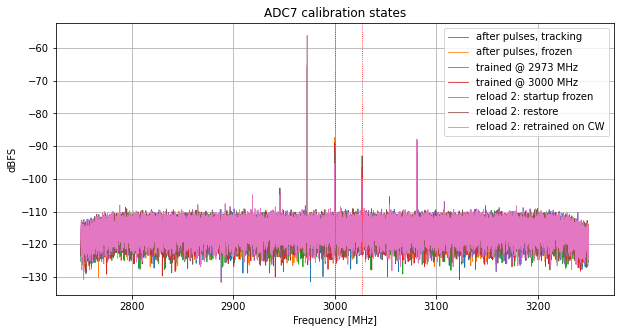

In [31]:
plt.figure(figsize=(10, 5))
PLOT_STATES = (
    "after pulses, tracking",
    "after pulses, frozen",
    "trained @ 2973 MHz",
    "trained @ 3000 MHz",
    "reload 2: startup frozen",
    "reload 2: restore",
    "reload 2: retrained on CW",
)
for label in PLOT_STATES:
    if label in spectra:
        plt.plot(*spectra[label], label=label, lw=0.8)
for f0 in expected_spurs().values():
    plt.axvline(f0, color="r", ls=":", lw=0.8)
plt.xlabel("Frequency [MHz]")
plt.ylabel("dBFS")
plt.title(f"ADC{ADC_CH} calibration states")
plt.legend()
plt.grid(True)

## 17. Optional: re-run foreground calibration

`restart_adc_tiles()` resets the ADC tiles (foreground calibration runs again), re-synchronizes MTS (DAC tiles are
reset too) and restores the default mixers. **Mute the input first**: PG269 requires no signal energy at k·Fs/M
during foreground calibration. First run: completed, MTS latency check passed, OCB2 recomputed, and the freeze
setting survived the reset.

In [32]:
ol.rf_control.register_map.amp_loop_setpoint = 0  # mute the CW tone
ol.rf_control.register_map.phs_loop_setpoint = 0

ol.restart_adc_tiles()
ol.check_mts_latency()
print(ol.report_mts_latency())
print("frozen after restart:", cal.is_frozen())
print(cal.report(ADC_CH))

< RFDC MTS Latency: >
  DAC Tile 0 Latency: 256, Offset: 2
  DAC Tile 1 Latency: 256, Offset: 2
  DAC Tile 2 Latency: 256, Offset: 2
  DAC Tile 3 Latency: 256, Offset: 2
  ADC Tile 0 Latency:  96, Offset: 1
  ADC Tile 1 Latency:  96, Offset: 1
  ADC Tile 2 Latency:  96, Offset: 1
  ADC Tile 3 Latency:  96, Offset: 1

frozen after restart: {0: True, 1: True, 2: True, 3: True, 4: True, 5: True, 6: True, 7: True}
ADC7 (tile 3, block 1): FROZEN
  OCB1: [4291887068, 4291821536, 4294443027, 4294836202, 0, 0, 0, 0]
  OCB2: [4294639567, 4294377421, 4292476867, 4294901725, 0, 0, 0, 0]
  GCB : [0, 65536, 4095, 65536, 0, 0, 0, 0]
  TSCB: [655825, 26935776, 7995595, 27394470, 5571014, 26804702, 393236, 27918755]
